<a href="https://colab.research.google.com/github/mygotracey/medicine_stockout/blob/main/01_data_exploration.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
df = pd.read_excel("salesdaily.xlsx")
print(df.shape)
print(df.columns.tolist())
print(df.head())
print(df.isna().sum())

(2106, 13)
['datum', 'M01AB', 'M01AE', 'N02BA', 'N02BE', 'N05B', 'N05C', 'R03', 'R06', 'Year', 'Month', 'Hour', 'Weekday Name']
   datum  M01AB  M01AE  N02BA  N02BE  N05B  N05C   R03  R06  Year  Month  \
0  41641    0.0   3.67    3.4  32.40   7.0   0.0   0.0  2.0  2014      1   
1  41642    8.0   4.00    4.4  50.60  16.0   0.0  20.0  4.0  2014      1   
2  41643    2.0   1.00    6.5  61.85  10.0   0.0   9.0  1.0  2014      1   
3  41644    4.0   3.00    7.0  41.10   8.0   0.0   3.0  0.0  2014      1   
4  41645    5.0   1.00    4.5  21.70  16.0   2.0   6.0  2.0  2014      1   

   Hour Weekday Name  
0   248     Thursday  
1   276       Friday  
2   276     Saturday  
3   276       Sunday  
4   276       Monday  
datum           0
M01AB           0
M01AE           0
N02BA           0
N02BE           0
N05B            0
N05C            0
R03             0
R06             0
Year            0
Month           0
Hour            0
Weekday Name    0
dtype: int64


In [3]:
df["date"] = pd.to_datetime(df["datum"], unit="D", origin="1899-12-30")
print(df["date"].min(), df["date"].max())
print("Days expected:", (df["date"].max() - df["date"].min()).days + 1)
print("Days present:", df["date"].nunique())
print(df.drop(columns=["datum","Year","Month","Hour"]).describe().T)

2014-01-02 00:00:00 2019-10-08 00:00:00
Days expected: 2106
Days present: 2106
        count                           mean                  min  \
M01AB  2106.0                       5.033683                  0.0   
M01AE  2106.0                        3.89583                  0.0   
N02BA  2106.0                       3.880441                  0.0   
N02BE  2106.0                      29.917095                  0.0   
N05B   2106.0                       8.853627                  0.0   
N05C   2106.0                       0.593522                  0.0   
R03    2106.0                       5.512262                  0.0   
R06    2106.0                       2.900198                  0.0   
date     2106  2016-11-19 12:00:00.000000256  2014-01-02 00:00:00   

                       25%                  50%                  75%  \
M01AB                  3.0                 4.99                 6.67   
M01AE                 2.34                 3.67                5.138   
N02BA         

In [4]:
df["date"] = pd.to_datetime(df["datum"], unit="D", origin="1899-12-30")
cats = ["M01AB","M01AE","N02BA","N02BE","N05B","N05C","R03","R06"]
daily = df.set_index("date")[cats]

# weekly totals, keeping only complete 7-day weeks
weekly = daily.resample("W-SUN").sum()
n_days = daily.resample("W-SUN").size()
weekly = weekly[n_days == 7]
print(weekly.shape, weekly.index.min(), weekly.index.max())

# share of zero-sales periods (daily vs weekly)
print((daily == 0).mean().round(2))
print((weekly == 0).mean().round(2))

# time-ordered split: last 52 weeks held out
train, test = weekly.iloc[:-52], weekly.iloc[-52:]
print(len(train), len(test), train.index.max(), test.index.min())

weekly.to_csv("weekly_sales.csv")

(300, 8) 2014-01-12 00:00:00 2019-10-06 00:00:00
M01AB    0.02
M01AE    0.02
N02BA    0.04
N02BE    0.01
N05B     0.02
N05C     0.68
R03      0.23
R06      0.12
dtype: float64
M01AB    0.00
M01AE    0.00
N02BA    0.00
N02BE    0.00
N05B     0.00
N05C     0.12
R03      0.00
R06      0.00
dtype: float64
248 52 2018-10-07 00:00:00 2018-10-14 00:00:00


In [5]:
# Biggest week divided by the typical (median) week, per drug
print((weekly.max() / weekly.median()).round(1))

# The 5 biggest weeks for N02BE
print(weekly["N02BE"].sort_values(ascending=False).head(5))

M01AB    1.9
M01AE    2.0
N02BA    2.3
N02BE    2.8
N05B     2.7
N05C     4.2
R03      3.7
R06      3.7
dtype: float64
date
2017-01-01    546.899
2019-01-27    478.300
2015-10-18    423.174
2016-10-09    418.187
2019-01-20    384.050
Name: N02BE, dtype: float64


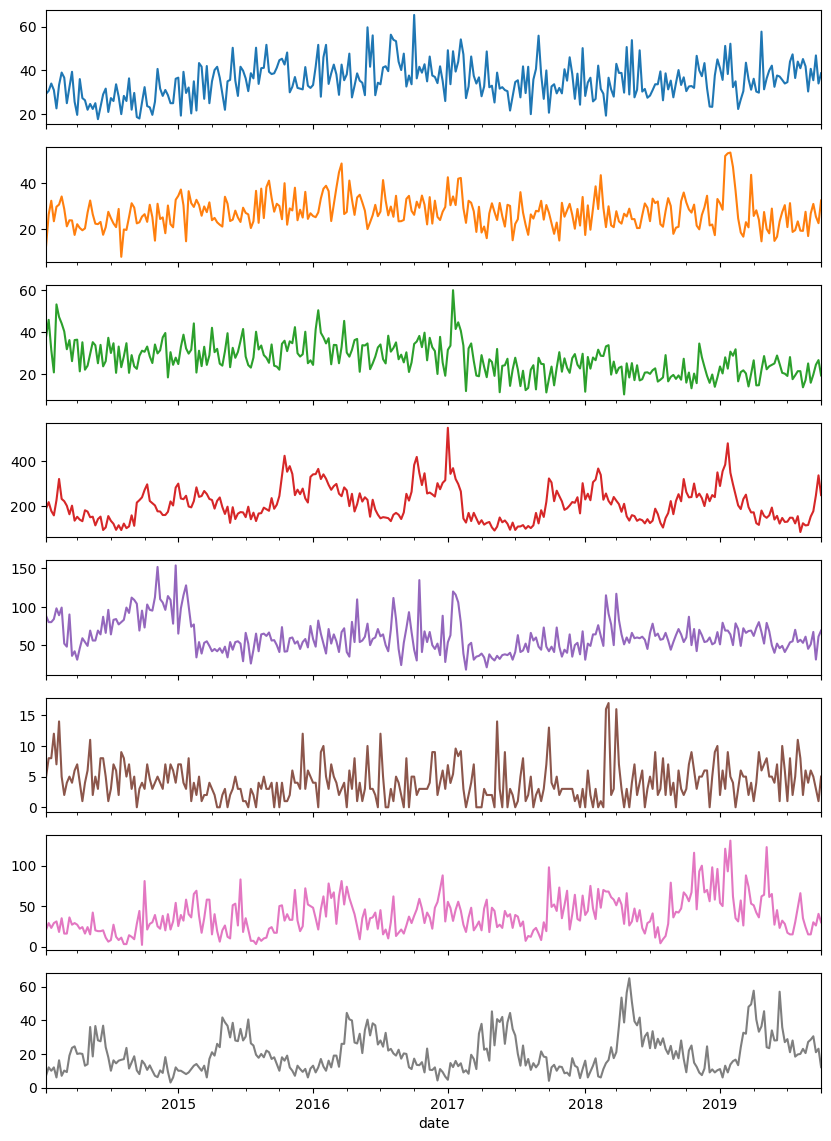

In [6]:
import matplotlib.pyplot as plt
weekly.plot(subplots=True, figsize=(10, 14), legend=False)
plt.show()